<h1>CRISP DM template (fi)</h1>

<h2>1. Business understanding</h2>

   - Määritellään ratkaistava liiketoimintaongelma (business problem).
   - Tavoitteena on selvittää analyysin päämäärä (goal), vaatimukset (requirements), rajoitteet (constraints) ja odotettu lopputulos (expected outcome).

The goal of this project is to build a text generator using a Transformer model. The model will be trained on Sherlock Holmes text from Project Gutenberg.

The aim is to understand how a Transformer learns from text and how different model settings affect the quality of generated text.

<h2>2. Data understanding</h2>

   - Kerätään ja tutkitaan saatavilla olevaa dataa.
   - Tässä kartoitetaan datan ominaisuudet, kuten muuttujatyypit ja arvojakaumat, sekä mahdolliset laatuongelmat (quality issues), kuten puuttuvat arvot (missing values), poikkeamat (outliers) ja järjettömät arvot (nonsensical values).

The dataset consists of the book `The case-book of Sherlock Holmes by Arthur Conan Doyle`. It contains English language stories about Sherlock Holmes and provides the material for training the text generation model.

In [16]:
#%pip install sentencepiece (run if needed)

In [2]:
import os

import numpy as np
import keras
import sentencepiece as spm

print(f"Keras version: {keras.__version__}")
print(f"Keras backend: {keras.config.backend()}")

Keras version: 3.15.1
Keras backend: tensorflow


In [11]:
file_path = "./txt/The_Project_Gutenberg.txt"
size_bytes = os.path.getsize(file_path)

with open(file_path, 'r', encoding='utf-8-sig') as file: # load the project gutenberg text
    text = file.read()

print(f"Text length: {len(text)} characters")
print(f'File size: {round(size_bytes / 1024, 2)} KB')
print(f"First 100 characters: {text[:100]}")

Text length: 473158 characters
File size: 472.33 KB
First 100 characters: The Project Gutenberg eBook of The case-book of Sherlock Holmes
    
This eBook is for the use of an


As we can see, the dataset length consist of 473158 characters. The first 100 characters show the beginning of the book.

<h2>3. Data preparation</h2>

   - Data siivotaan, muunnetaan ja valitaan olennaiset piirteet (features).
   - Kaikki nämä vaiheet tulee dokumentoida niin tarkasti, että ne ovat myöhemmin täysin toistettavissa.



In [12]:
# train SentencePiece model
# save text to a temporary file for SentencePiece training
temp_file = 'gutenberg_temp.txt'
with open(temp_file, 'w', encoding='utf-8') as f:
    f.write(text)

# train SentencePiece model
vocab_size = 2000  # lets try with smaller amount of tokens
model_prefix = 'gutenberg_sp'

spm.SentencePieceTrainer.train(
    input=temp_file,
    model_prefix=model_prefix,
    vocab_size=vocab_size,
    character_coverage=1.0, 
    model_type='bpe',
    user_defined_symbols=['<PAD>', '<UNK>']
)

# load the trained tokenizer
sp = spm.SentencePieceProcessor()
sp.load(f"{model_prefix}.model")

# test tokenization
test_text = "It was from the Carlton Club"
tokens = sp.encode_as_pieces(test_text)

print(f"Tokenized example: {tokens}")
print(f"Vocabulary size: {sp.get_piece_size()}")

Tokenized example: ['▁It', '▁was', '▁from', '▁the', '▁C', 'ar', 'lt', 'on', '▁C', 'l', 'ub']
Vocabulary size: 2000


In [13]:
# prepare training data
# tokenize the text
seq_length = 64
pieces = sp.encode_as_ids(text)
print(f"Total tokens: {len(pieces)}")

# create sequences
sequences = []
for i in range(0, len(pieces) - seq_length):
    # Input: first seq_length tokens, Target: next seq_length tokens (shifted by 1)
    sequences.append(pieces[i:i+seq_length+1])

# convert to NumPy arrays
sequences = np.array(sequences)
inputs = sequences[:, :-1]  # All tokens except the last one
targets = sequences[:, 1:]  # All tokens except the first one

print(f"Number of sequences: {len(sequences)}")
print(f"Input shape: {inputs.shape}")
print(f"Target shape: {targets.shape}")

# Split into training and validation sets: the first 90 % of the text for training,
# the rest for validation. Neighbouring windows share 63 of their 64 tokens, so a
# random split would put almost the same windows in both sets. Skipping seq_length
# windows at the split point leaves no shared tokens between the sets.
split = int(0.9 * len(sequences))
train_inputs, train_targets = inputs[:split], targets[:split]
val_inputs, val_targets = inputs[split + seq_length:], targets[split + seq_length:]

Total tokens: 138589
Number of sequences: 138525
Input shape: (138525, 64)
Target shape: (138525, 64)


<h2>4. Modeling</h2>

 - Valitaan koneoppimismenetelmä, opetetaan malli ja validoidaan se (validation).
 - Dokumentointiin on sisällytettävä tarkasti valittu menetelmä, käytetyt parametrit sekä mitattu mallin suorituskyky.
 - Millä perusteella tehty valinnat
 - Taulukko on hyvä viestimiseen
 - Ei tarvitse olla yksityiskohtainen, mutta selitetään miksi on päädytty lopputulokseen.

In [14]:
# define the model
def get_positional_encoding(max_len, d_model):
    """Create sinusoidal positional encoding."""
    positions = np.arange(max_len)[:, np.newaxis]
    angles = np.arange(d_model)[np.newaxis, :] / d_model
    angles = 1 / (10000**angles)

    pos_encoding = positions * angles
    pos_encoding[:, 0::2] = np.sin(pos_encoding[:, 0::2])
    pos_encoding[:, 1::2] = np.cos(pos_encoding[:, 1::2])

    return pos_encoding

# define model parameters
embed_dim = 64
num_heads = 2
ff_dim = 128
num_layers = 2

# create the model
inputs = keras.Input(shape=(seq_length,))
embedding_layer = keras.layers.Embedding(sp.get_piece_size(), embed_dim)(inputs)

# add positional encoding
pos_encoding = get_positional_encoding(seq_length, embed_dim)
x = embedding_layer + pos_encoding

# transformer blocks
for _ in range(num_layers):
    # Multi-head attention with causal mask
    attention_output = keras.layers.MultiHeadAttention(
        num_heads=num_heads,
        key_dim=embed_dim // num_heads,
        dropout=0.1
    )(x, x, use_causal_mask=True)

    # Add & Norm
    x = keras.layers.LayerNormalization(epsilon=1e-6)(x + attention_output)

    # Feed-forward network
    ffn = keras.Sequential([
        keras.layers.Dense(ff_dim, activation="relu"),
        keras.layers.Dense(embed_dim),
        keras.layers.Dropout(0.1)
    ])
    ffn_output = ffn(x)

    # Add & Norm
    x = keras.layers.LayerNormalization(epsilon=1e-6)(x + ffn_output)

# final output layer
outputs = keras.layers.Dense(sp.get_piece_size())(x)

# create model
model = keras.Model(inputs=inputs, outputs=outputs)

# compile model
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=3e-4),
    loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=['accuracy']
)

model.summary()

Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape              ┃         Param # ┃ Connected to               ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)      │ (None, 64)                │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ embedding (Embedding)         │ (None, 64, 64)            │         128,000 │ input_layer[0][0]          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ add (Add)                     │ (None, 64, 64)            │               0 │ embedding[0][0]            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ multi_head_attention          │ (None, 64, 64)            │          16,640 │ add[0][0], add[0][0]       │
│ (MultiHeadAttention)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ add_1 (Add)                   │ (None, 64, 64)            │               0 │ add[0][0],                 │
│                               │                           │                 │ multi_head_attention[0][0] │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ layer_normalization           │ (None, 64, 64)            │             128 │ add_1[0][0]                │
│ (LayerNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ sequential (Sequential)       │ (None, 64, 64)            │          16,576 │ layer_normalization[0][0]  │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ add_2 (Add)                   │ (None, 64, 64)            │               0 │ layer_normalization[0][0], │
│                               │                           │                 │ sequential[0][0]           │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ layer_normalization_1         │ (None, 64, 64)            │             128 │ add_2[0][0]                │
│ (LayerNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ multi_head_attention_1        │ (None, 64, 64)            │          16,640 │ layer_normalization_1[0][… │
│ (MultiHeadAttention)          │                           │                 │ layer_normalization_1[0][… │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ add_3 (Add)                   │ (None, 64, 64)            │               0 │ layer_normalization_1[0][… │
│                               │                           │                 │ multi_head_attention_1[0]… │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ layer_normalization_2         │ (None, 64, 64)            │             128 │ add_3[0][0]                │
│ (LayerNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ sequential_1 (Sequential)     │ (None, 64, 64)            │          16,576 │ layer_normalization_2[0][… │
├───────────────────────────────┼───────────────────────────┼───────────────

 Total params: 324,944 (1.24 MB)

 Trainable params: 324,944 (1.24 MB)

 Non-trainable params: 0 (0.00 B)

In [15]:
# train the model
batch_size = 32
epochs = 5

history = model.fit(
    train_inputs, train_targets,
    validation_data=(val_inputs, val_targets),
    batch_size=batch_size,
    epochs=epochs,
    callbacks=[
        keras.callbacks.EarlyStopping(patience=3, restore_best_weights=True, verbose=1),
        keras.callbacks.ReduceLROnPlateau(factor=0.5, patience=1),
        keras.callbacks.ModelCheckpoint('gutenberg_best_model.keras', save_best_only=True)
    ]
)

Epoch 1/5
3896/3896 ━━━━━━━━━━━━━━━━━━━━ 268s 67ms/step - accuracy: 0.1551 - loss: 4.7437 - val_accuracy: 0.1403 - val_loss: 5.2901 - learning_rate: 3.0000e-04
Epoch 2/5
3896/3896 ━━━━━━━━━━━━━━━━━━━━ 237s 61ms/step - accuracy: 0.2258 - loss: 3.7590 - val_accuracy: 0.1540 - val_loss: 5.4796 - learning_rate: 3.0000e-04
Epoch 3/5
3896/3896 ━━━━━━━━━━━━━━━━━━━━ 232s 59ms/step - accuracy: 0.2596 - loss: 3.4634 - val_accuracy: 0.1582 - val_loss: 5.6475 - learning_rate: 1.5000e-04
Epoch 4/5
3896/3896 ━━━━━━━━━━━━━━━━━━━━ 238s 61ms/step - accuracy: 0.2747 - loss: 3.3465 - val_accuracy: 0.1600 - val_loss: 5.7385 - learning_rate: 7.5000e-05
Epoch 4: early stopping
Restoring model weights from the end of the best epoch: 1.


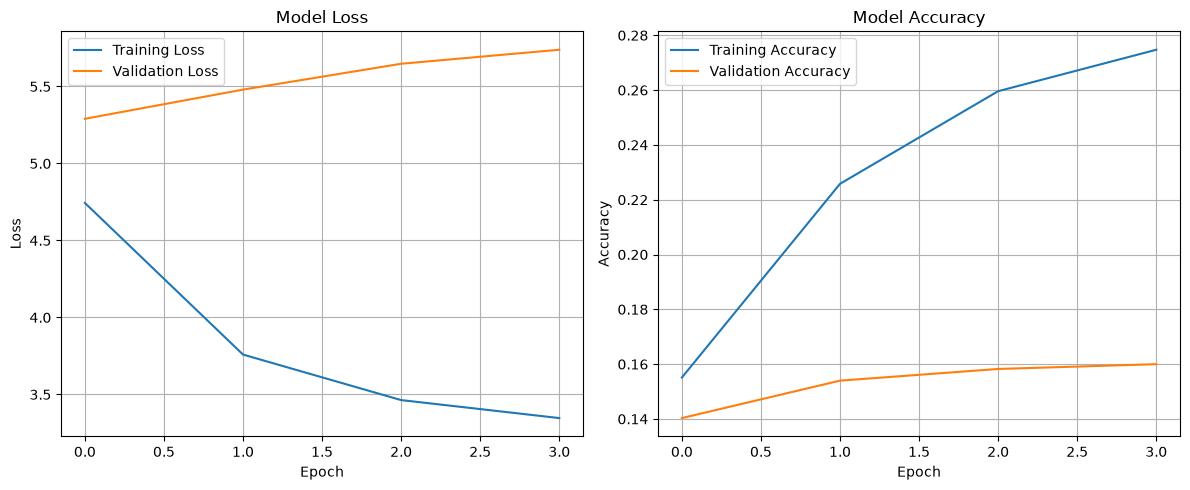

In [16]:
# plot training metrics
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.grid()
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.grid()
plt.legend()

plt.tight_layout()
plt.show()

In [18]:
# save the model
model.save('gutenberg_model.keras')
print("Model saved as 'gutenberg_model.keras'")

Model saved as 'gutenberg_model.keras'


In [19]:
def generate_text(model, sp, prompt, num_tokens=100, temperature=1.0):
    """
    Generate text autoregressively.

    Args:
        temperature: Controls randomness
            - Low (0.1-0.5): Focused, repetitive
            - Medium (0.7-1.0): Balanced
            - High (1.5+): Creative, chaotic
    """
    # Encode the prompt
    input_ids = sp.encode_as_ids(prompt)

    # Rest of your generation code stays the same...
    if len(input_ids) < seq_length:
        padding_length = seq_length - len(input_ids)
        input_ids = [0] * padding_length + input_ids
    else:
        padding_length = 0
        input_ids = input_ids[-seq_length:]

    # Generated tokens
    generated_ids = list(input_ids[padding_length:])

    # Generate text token by token
    for _ in range(num_tokens):
        x = np.array([input_ids])
        predictions = model.predict(x, verbose=0)[0]
        logits = predictions[-1]
        logits = logits / temperature
        exp_logits = np.exp(logits - np.max(logits))
        probs = exp_logits / np.sum(exp_logits)
        next_token = np.random.choice(len(probs), p=probs)
        generated_ids.append(next_token)
        input_ids = input_ids[1:] + [next_token]

    # Decode the generated sequence
    generated_text = sp.decode(generated_ids)

    return generated_text

In [20]:
# generate sample text
prompts = [
    "It was from the Carlton Club",
    "Have you ever heard of Baron Gruner?",
    "Then you will sympathize with the client",
    "Our visitor was greatly disturbed"
]

for prompt in prompts:
    print(f"\nPrompt: {prompt}")
    generated = generate_text(model, sp, prompt, num_tokens=100, temperature=1.2)
    print(generated)


Prompt: It was from the Carlton Club
It was from the Carlton Club." "Csical, Mr. The date is When I make it----ched. If wendus it was scandaimed her servanticars even next and shall I. It must on to brother off when I can because he found it is,' is all with you would be his hurried e, and everything all behind them? This is the big, dark-n's the room, but I certainly be chanced that cot drill had brought back

Prompt: Have you ever heard of Baron Gruner?
Have you ever heard of Baron Gruner? I hardly argly in goel lit abggyourow and often now ket it!" chessear that sound, "Have you, and he is already learpterby. Aotipent about, so whose a year. "f walk forward and that you have excitedly con them before how think we may do now? Un! He get him you will indeed your quietyers?" said Holmes showed the este that they can speak

Prompt: Then you will sympathize with the client
Then you will sympathize with the client permice--a! The we were told me, and if you the solicaged him. It is the r

In [ ]:
# load model (if you're starting a new session)
# uncomment these lines to load a previously saved model
"""
# Load saved model
model = keras.models.load_model('gutenberg_model.keras')

# Load SentencePiece tokenizer
sp = spm.SentencePieceProcessor()
sp.load('gutenberg_sp.model')

# Test generation
prompt = "Our visitor was greatly disturbed"
generated = generate_text(model, sp, prompt, num_tokens=150, temperature=1.0)
print(generated)
"""

<h2>5. Evaluation</h2>

 - Arvioidaan mallin todellinen onnistuminen.
 - Selvitetään, kuinka hyvin malli vastaa sille alun perin asetettuihin liiketoimintavaatimuksiin (business requirements).<br>
 - Ei katsota mallin suorituskykyä (tämä tehdään kappaleessa 4), vaan palataan takaisin kappaleeseen 1. ja millä tavalla saavutetut tulokset vertautuu alkuperäisiin tavoitteisiin.

<h2>6. Deployment</h2>

- Malli viedään käytäntöön (deployment).
- Tähän sisältyy tulosten viestiminen ja suositusten luominen siitä, miten mallia tulisi hyödyntää käytännössä tai mitä jatkotoimenpiteitä tulisi tehdä.